# Day 1: EDA – Laptop price (Smartprix, ₹)

Goal: understand what drives laptop prices before modelling. Input: `data/clean.csv` (made by `src/clean.py`).

In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

# works whether VS Code runs the notebook from /notebooks or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "data" / "clean.csv")
print(df.shape)
df.head()

(940, 23)


,brand_name,model,price,processor_brand,iter,threads_num,core_num,ram_num,memory_type,memory_size,...,display_size,Touch_Screen,warrenty,res_w,res_h,pixels_mp,gpu_vram_gb,gpu_num,gpu_family,log_price
0,Lenovo,Lenovo V15 G4 ‎83CR000VIN Laptop (AMD Ryzen 7 ...,39990,AMD,Ryzen 7,16.0,8.0,16,SSD,512,...,15.6,False,1,1920,1080,2.0736,0.0,0.0,Integrated,10.596385
1,Samsung,Samsung Galaxy Book 4 NP750XGJ-LG4IN Laptop (1...,36990,Intel,Core i3,8.0,8.0,8,SSD,512,...,15.6,False,1,1920,1080,2.0736,0.0,0.0,Integrated,10.518403
2,HP,HP 15-fc0154AU Laptop (AMD Ryzen 3 7320U/ 8GB/...,30290,AMD,Ryzen 3,8.0,8.0,8,SSD,512,...,15.6,False,1,1920,1080,2.0736,0.0,0.0,Integrated,10.318573
3,MSI,MSI Titan 18 HX Gaming Laptop (Intel Core Ultr...,359900,Intel,Core Ultra 9,24.0,24.0,32,SSD,1000,...,18.0,False,3,3840,2400,9.2160,12.0,5070.0,RTX,12.793581
4,Asus,Asus Vivobook 16X 2023 K3605ZC-MBN544WS Laptop...,59140,Intel,Core i5,16.0,12.0,16,SSD,512,...,16.0,False,1,1920,1200,2.3040,4.0,3050.0,RTX,10.987663


In [11]:
df.info()
df[["price", "ram_num", "memory_size", "display_size", "pixels_mp", "gpu_vram_gb"]].describe().round(1)

<class 'pandas.DataFrame'>
RangeIndex: 940 entries, 0 to 939
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   brand_name       940 non-null    str    
 1   model            940 non-null    str    
 2   price            940 non-null    int64  
 3   processor_brand  940 non-null    str    
 4   iter             940 non-null    str    
 5   threads_num      940 non-null    float64
 6   core_num         940 non-null    float64
 7   ram_num          940 non-null    int64  
 8   memory_type      940 non-null    str    
 9   memory_size      940 non-null    int64  
 10  gpu_brand        940 non-null    str    
 11  gpu_type         940 non-null    str    
 12  os               940 non-null    str    
 13  display_size     940 non-null    float64
 14  Touch_Screen     940 non-null    bool   
 15  warrenty         940 non-null    int64  
 16  res_w            940 non-null    int64  
 17  res_h            940 non-nu

,price,ram_num,memory_size,display_size,pixels_mp,gpu_vram_gb
count,940.0,940.0,940.0,940.0,940.0,940.0
mean,88898.2,15.9,670.1,15.2,2.7,2.5
std,72279.8,8.1,358.3,1.0,1.4,3.6
min,10990.0,4.0,32.0,11.6,1.0,0.0
25%,45722.5,8.0,512.0,14.0,2.1,0.0
50%,66990.0,16.0,512.0,15.6,2.1,0.0
75%,99992.2,16.0,1000.0,15.6,2.3,6.0
max,500990.0,96.0,4000.0,18.0,9.2,24.0


## 1. Target: price vs log(price)

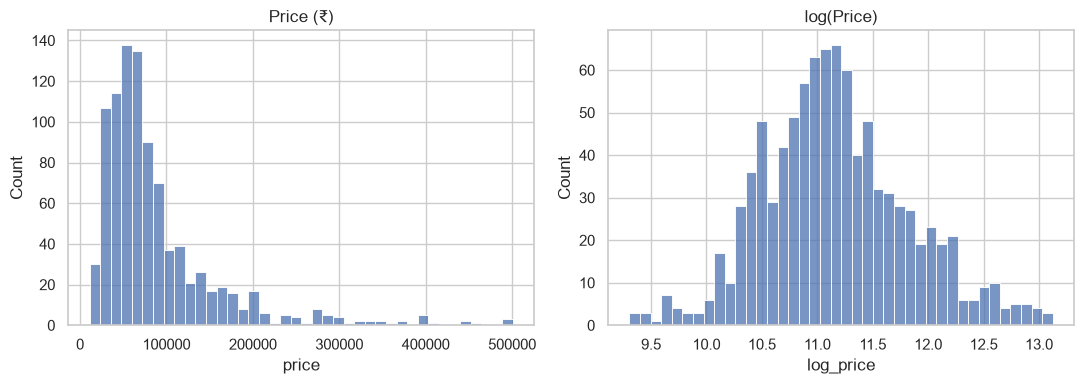

skew: 2.51 -> after log: 0.32


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df.price, bins=40, ax=ax[0]); ax[0].set_title("Price (₹)")
sns.histplot(df.log_price, bins=40, ax=ax[1]); ax[1].set_title("log(Price)")
plt.tight_layout()
plt.savefig(FIG / "price_distribution.png", dpi=150)
plt.show()
print("skew:", round(df.price.skew(), 2), "-> after log:", round(df.log_price.skew(), 2))

## 2. RAM and storage

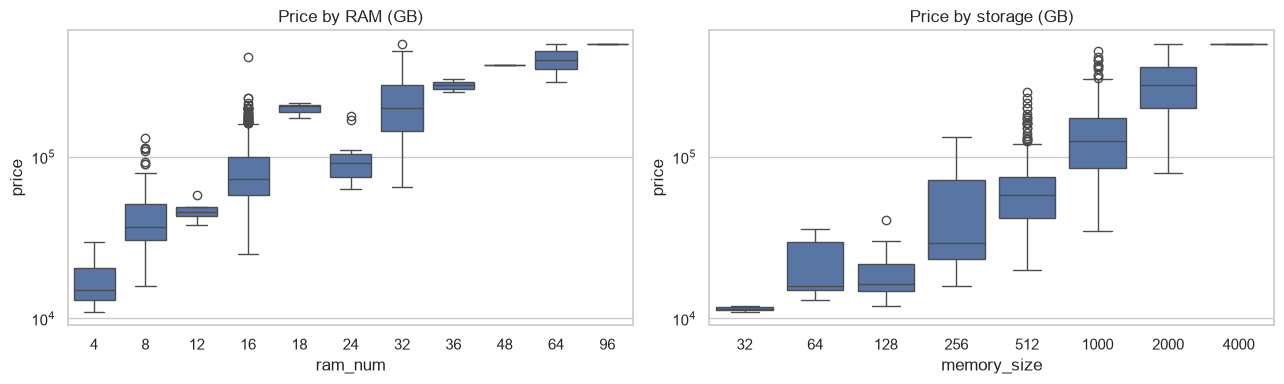

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="ram_num", y="price", ax=ax[0]); ax[0].set_title("Price by RAM (GB)")
sns.boxplot(data=df, x="memory_size", y="price", ax=ax[1]); ax[1].set_title("Price by storage (GB)")
for a in ax:
    a.set_yscale("log")
plt.tight_layout()
plt.savefig(FIG / "price_by_ram_storage.png", dpi=150)
plt.show()

## 3. Brand

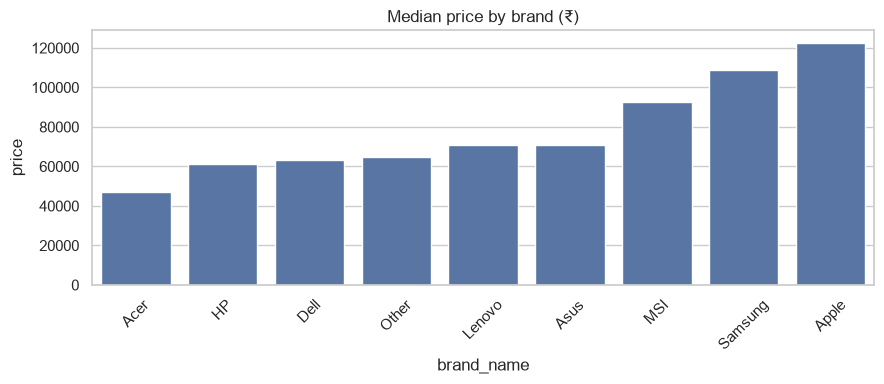

brand_name
HP         203
Lenovo     188
Asus       153
Acer       110
MSI         96
Other       84
Dell        64
Apple       22
Samsung     20
Name: count, dtype: int64

In [14]:
order = df.groupby("brand_name").price.median().sort_values().index
plt.figure(figsize=(9, 4))
sns.barplot(data=df, x="brand_name", y="price", order=order, estimator="median", errorbar=None)
plt.title("Median price by brand (₹)"); plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG / "price_by_brand.png", dpi=150)
plt.show()
df.brand_name.value_counts()

## 4. GPU

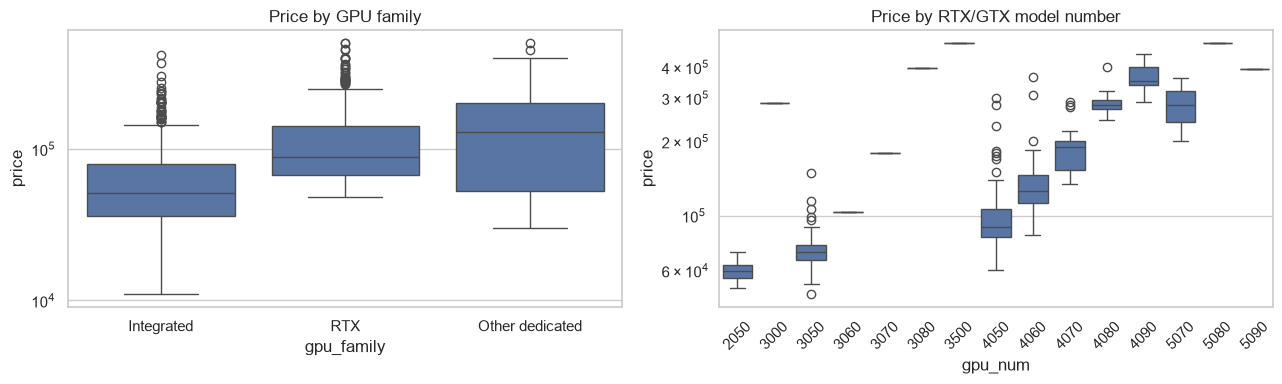

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="gpu_family", y="price", ax=ax[0]); ax[0].set_title("Price by GPU family")

d = df[df.gpu_num > 0].assign(gpu_num=lambda x: x.gpu_num.astype(int))
sns.boxplot(data=d, x="gpu_num", y="price", order=sorted(d.gpu_num.unique()), ax=ax[1])
ax[1].set_title("Price by RTX/GTX model number"); ax[1].tick_params(axis="x", rotation=45)
for a in ax:
    a.set_yscale("log")
plt.tight_layout()
plt.savefig(FIG / "price_by_gpu.png", dpi=150)
plt.show()

## 5. Screen

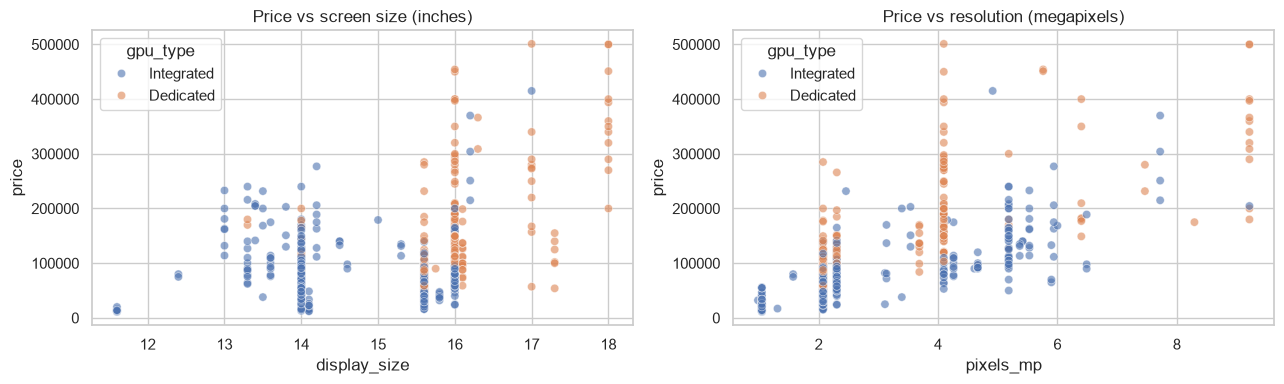

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="display_size", y="price", hue="gpu_type", alpha=0.6, ax=ax[0])
sns.scatterplot(data=df, x="pixels_mp", y="price", hue="gpu_type", alpha=0.6, ax=ax[1])
ax[0].set_title("Price vs screen size (inches)"); ax[1].set_title("Price vs resolution (megapixels)")
plt.tight_layout()
plt.savefig(FIG / "price_vs_screen.png", dpi=150)
plt.show()

## 6. Correlations

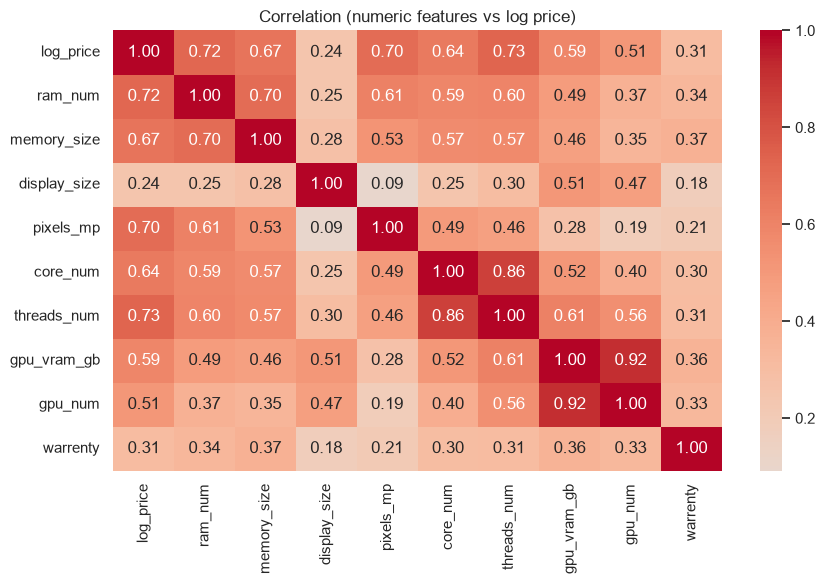

In [17]:
num = ["log_price", "ram_num", "memory_size", "display_size", "pixels_mp",
       "core_num", "threads_num", "gpu_vram_gb", "gpu_num", "warrenty"]
plt.figure(figsize=(9, 6))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation (numeric features vs log price)")
plt.tight_layout()
plt.savefig(FIG / "correlations.png", dpi=150)
plt.show()

## 7. Outliers and split check

In [18]:
print("unique model names:", df.model.nunique(), "of", len(df), "rows")
df.nlargest(5, "price")[["brand_name", "price", "ram_num", "memory_size", "gpu_family"]]

unique model names: 881 of 940 rows


,brand_name,price,ram_num,memory_size,gpu_family
742,MSI,500990,64,4000,RTX
10,MSI,499999,96,4000,RTX
709,MSI,499990,32,2000,Other dedicated
884,Dell,454236,32,2000,RTX
892,Dell,451099,64,1000,RTX


## Findings (fill in after looking at the plots)

- Which features move price the most?
- Does the GPU model matter more than the brand?
- Which brands are premium vs budget?
- Any outliers or odd patterns worth mentioning in the README?

Next: Day 2 – baseline vs XGBoost with `GroupKFold` on `model`.

## Findings

- **RAM and storage drive price.** Median price is about ₹37k at 8GB, ₹73k at 16GB and ₹200k at 32GB, so it roughly doubles with each step. Storage shows the same pattern: about ₹58k at 512GB and ₹126k at 1TB. RAM, CPU threads, resolution and storage each correlate 0.67-0.73 with log price, while screen size is weak (0.24).
- **GPU model matters a lot.** Median price rises steadily with the RTX number: about ₹59k (2050), ₹89k (4050), ₹126k (4060), ₹190k (4070) and ₹280k (4080). Laptops with an RTX card have a median of about ₹88k, against about ₹51k for integrated graphics.
- **GPU matters more than brand.** For the same RTX 4060, brands with 10+ listings have medians between about ₹115k and ₹135k. That's a smaller spread than the ₹64k jump from a 4060 to a 4070. Brand mostly matters through its product mix: 69% of MSI laptops have a dedicated GPU, which helps explain why MSI looks expensive. I'll test this in the model.
- **Premium vs. budget brands.** Acer is cheapest (about ₹47k median), then HP and Dell (about ₹61-63k), Lenovo and Asus (about ₹71k), MSI (about ₹93k), Samsung (about ₹109k) and Apple (about ₹123k). Samsung and Apple have only about 20 listings each, so treat those numbers as rough.
- **Outliers and skew.** Prices are right-skewed (skew 2.6, falling to 0.3 after a log transform), so I predict log price. The five most expensive laptops are all above ₹4.5 lakh, mostly MSI and Dell machines with 32-96GB RAM and 1-4TB storage. I kept them because they're genuine high-end listings.
- **Caveat.** These are Smartprix listing prices in ₹ for a single snapshot, not final sale prices.